In [1]:
import polars as pl
from polars import col as c
from pathlib import Path

In [ ]:
reflectors_raw = pl.concat(
    [
        pl.read_csv(f).with_columns(pl.lit(f.stem).alias("scanner"))
        for f in Path("reflector_positions").glob("*.csv")
    ]
)

In [ ]:
reflectors = reflectors_raw.select(
    c.Name,
    x=pl.col("X[m]").str.strip_chars(" ").cast(pl.Float64),
    y=pl.col("Y[m]").str.strip_chars(" ").cast(pl.Float64),
    z=pl.col("Z[m]").str.strip_chars(" ").cast(pl.Float64),
    scanner=c.scanner.str.extract(r"ScanPos(\d{3})").cast(pl.Int64),
).sort(["x", "y", "z", "scanner"])

In [12]:
reflectors

Name,x,y,z,scanner
str,f64,f64,f64,i64
"""TP_006""",-1.541,-0.542,106.13,3
"""TP_003""",-1.541,-0.54,106.127,2
"""TP_004""",-1.54,-0.551,106.133,6
"""TP_006""",-1.536,-0.548,106.131,5
"""TP_002""",3.366,8.218,105.713,1
…,…,…,…,…
"""TP_002""",34.443,2.835,104.838,8
"""TP_005""",34.443,2.841,104.844,6
"""TP_001""",34.447,2.844,104.839,9


In [13]:
from plotnine import *

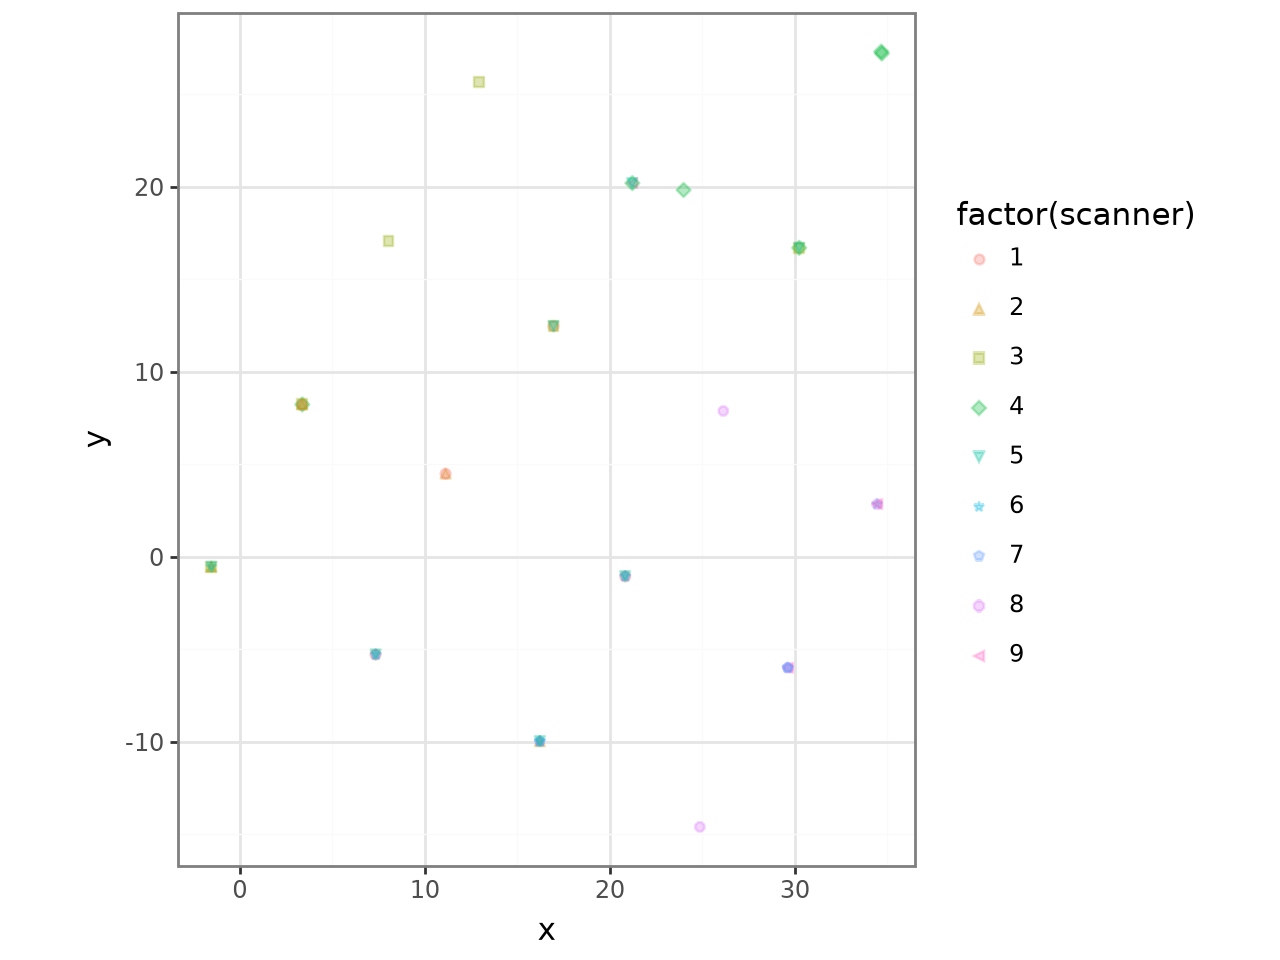

In [ ]:
(
    ggplot(reflectors)
    + geom_point(
        aes("x", "y", color="factor(scanner)", shape="factor(scanner)"), alpha=0.3
    )
    + theme_bw()
    + coord_fixed()
)

In [ ]:
refl_loc = (
    reflectors.join(reflectors, how="cross")
    .with_columns(
        diff=(
            (c.x - c.x_right) ** 2 + (c.y - c.y_right) ** 2 + (c.z - c.z_right) ** 2
        ).sqrt(),
    )
    .filter(
        # c.scanner != c.scanner_right,
        c.diff < 0.1
    )
    .group_by(
        [
            c.x.round().alias("group_x"),
            c.y.round().alias("group_y"),
            c.z.round().alias("group_z"),
        ]
    )
    .agg(
        pl.len(),
        x=c.x.mean(),
        y=c.y.mean(),
        z=c.z.mean(),
        diff=c.diff.mean(),
        x_s=c.x,
        y_s=c.y,
        z_s=c.z,
        diff_s=c.diff,
    )
)
refl_loc

group_x,group_y,group_z,len,x,y,z,diff,x_s,y_s,z_s,diff_s
f64,f64,f64,u32,f64,f64,f64,f64,list[f64],list[f64],list[f64],list[f64]
26.0,8.0,106.0,1,26.13,7.873,105.663,0.0,[26.13],[7.873],[105.663],[0.0]
13.0,26.0,106.0,1,12.936,25.668,105.538,0.0,[12.936],[25.668],[105.538],[0.0]
7.0,-5.0,106.0,16,7.34325,-5.29025,105.8585,0.009315,"[7.333, 7.333, … 7.35]","[-5.288, -5.288, … -5.292]","[105.856, 105.856, … 105.862]","[0.0, 0.011402, … 0.0]"
21.0,-1.0,106.0,16,20.82725,-1.06,105.832,0.007255,"[20.823, 20.823, … 20.833]","[-1.054, -1.054, … -1.06]","[105.833, 105.833, … 105.836]","[0.0, 0.009539, … 0.0]"
-2.0,-1.0,106.0,16,-1.5395,-0.54525,106.13025,0.006153,"[-1.541, -1.541, … -1.536]","[-0.542, -0.542, … -0.548]","[106.13, 106.13, … 106.131]","[0.0, 0.003606, … 0.0]"
…,…,…,…,…,…,…,…,…,…,…,…
3.0,8.0,106.0,16,3.373,8.228,105.71675,0.010159,"[3.366, 3.366, … 3.378]","[8.218, 8.218, … 8.227]","[105.713, 105.713, … 105.715]","[0.0, 0.014, … 0.0]"
34.0,3.0,105.0,9,34.444333,2.84,104.840333,0.005657,"[34.443, 34.443, … 34.447]","[2.835, 2.835, … 2.844]","[104.838, 104.838, … 104.839]","[0.0, 0.008485, … 0.0]"
35.0,27.0,105.0,2,34.6815,27.2465,105.1465,0.0,"[34.664, 34.699]","[27.299, 27.194]","[105.133, 105.16]","[0.0, 0.0]"


The reflector closest to 0,0 (the first pole) is used as the new origin

In [ ]:
shifts = (
    refl_loc.filter(c.x.abs() < 2, c.y.abs() < 2)
    .select(c.x, c.y)
    .to_dict(as_series=False)
)
shifts

{'x': [-1.5394999999999999], 'y': [-0.54525]}

In [48]:
x_shift: float = shifts["x"][0]
y_shift: float = shifts["y"][0]

In [ ]:
refl_loc = refl_loc.with_columns(x_shifted=c.x - x_shift, y_shifted=c.y - y_shift)
refl_loc

group_x,group_y,group_z,len,x,y,z,diff,x_s,y_s,z_s,diff_s,x_shift,y_shift,x_shifted,y_shifted
f64,f64,f64,u32,f64,f64,f64,f64,list[f64],list[f64],list[f64],list[f64],f64,f64,f64,f64
26.0,8.0,106.0,1,26.13,7.873,105.663,0.0,[26.13],[7.873],[105.663],[0.0],27.6695,8.41825,27.6695,8.41825
13.0,26.0,106.0,1,12.936,25.668,105.538,0.0,[12.936],[25.668],[105.538],[0.0],14.4755,26.21325,14.4755,26.21325
7.0,-5.0,106.0,16,7.34325,-5.29025,105.8585,0.009315,"[7.333, 7.333, … 7.35]","[-5.288, -5.288, … -5.292]","[105.856, 105.856, … 105.862]","[0.0, 0.011402, … 0.0]",8.88275,-4.745,8.88275,-4.745
21.0,-1.0,106.0,16,20.82725,-1.06,105.832,0.007255,"[20.823, 20.823, … 20.833]","[-1.054, -1.054, … -1.06]","[105.833, 105.833, … 105.836]","[0.0, 0.009539, … 0.0]",22.36675,-0.51475,22.36675,-0.51475
-2.0,-1.0,106.0,16,-1.5395,-0.54525,106.13025,0.006153,"[-1.541, -1.541, … -1.536]","[-0.542, -0.542, … -0.548]","[106.13, 106.13, … 106.131]","[0.0, 0.003606, … 0.0]",0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3.0,8.0,106.0,16,3.373,8.228,105.71675,0.010159,"[3.366, 3.366, … 3.378]","[8.218, 8.218, … 8.227]","[105.713, 105.713, … 105.715]","[0.0, 0.014, … 0.0]",4.9125,8.77325,4.9125,8.77325
34.0,3.0,105.0,9,34.444333,2.84,104.840333,0.005657,"[34.443, 34.443, … 34.447]","[2.835, 2.835, … 2.844]","[104.838, 104.838, … 104.839]","[0.0, 0.008485, … 0.0]",35.983833,3.38525,35.983833,3.38525
35.0,27.0,105.0,2,34.6815,27.2465,105.1465,0.0,"[34.664, 34.699]","[27.299, 27.194]","[105.133, 105.16]","[0.0, 0.0]",36.221,27.79175,36.221,27.79175


Direction from the southern most line.

In [57]:
refl_loc = refl_loc.with_columns(
    label=pl.concat_str(
        [
            pl.col("x_shifted").round(2).cast(pl.String),
            pl.col("y_shifted").round(2).cast(pl.String),
        ],
        separator=", ",
    )
)

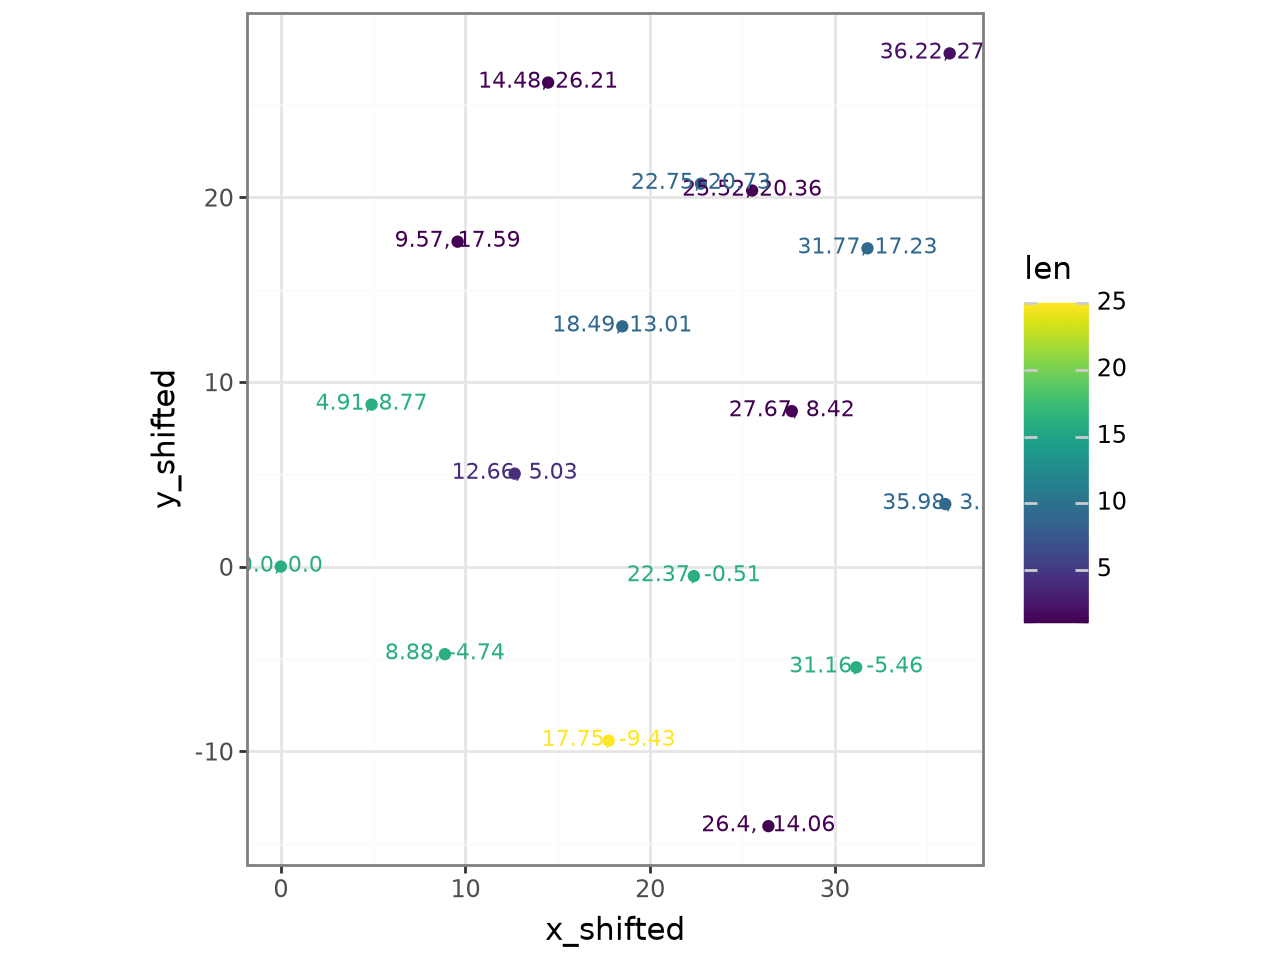

In [ ]:
(
    ggplot(refl_loc, aes("x_shifted", "y_shifted", label="label", colour="len"))
    + geom_point()
    + coord_fixed()
    + geom_text(nudge_y=0.1, size=8)
    + theme_bw()
)

In [54]:
import polars_ds as pds

In [ ]:
bottom_row = refl_loc.filter(
    c.x_shifted.floor().is_in([0.0, 8, 17, 26]),
    # c.y.floor().is_in([0., 8, 17, 26])
).sort(c.x)
bottom_row

group_x,group_y,group_z,len,x,y,z,diff,x_s,y_s,z_s,diff_s,x_shift,y_shift,x_shifted,y_shifted,label
f64,f64,f64,u32,f64,f64,f64,f64,list[f64],list[f64],list[f64],list[f64],f64,f64,f64,f64,str
-2.0,-1.0,106.0,16,-1.5395,-0.54525,106.13025,0.006153,"[-1.541, -1.541, … -1.536]","[-0.542, -0.542, … -0.548]","[106.13, 106.13, … 106.131]","[0.0, 0.003606, … 0.0]",0.0,0.0,0.0,0.0,"""0.0, 0.0"""
7.0,-5.0,106.0,16,7.34325,-5.29025,105.8585,0.009315,"[7.333, 7.333, … 7.35]","[-5.288, -5.288, … -5.292]","[105.856, 105.856, … 105.862]","[0.0, 0.011402, … 0.0]",8.88275,-4.745,8.88275,-4.745,"""8.88, -4.74"""
16.0,-10.0,106.0,25,16.2138,-9.9766,105.8478,0.011051,"[16.206, 16.206, … 16.219]","[-9.986, -9.986, … -9.976]","[105.855, 105.855, … 105.855]","[0.0, 0.016401, … 0.0]",17.7533,-9.43135,17.7533,-9.43135,"""17.75, -9.43"""
25.0,-15.0,105.0,1,24.865,-14.603,105.486,0.0,[24.865],[-14.603],[105.486],[0.0],26.4045,-14.05775,26.4045,-14.05775,"""26.4, -14.06"""


In [ ]:
direction_slope = (
    bottom_row.select(pds.lin_reg(c.x_shifted, target=c.y_shifted, add_bias=False))
    .item()
    .item()
)

direction_slope

-0.5321950491231829

In [88]:
import numpy as np

theta = np.arctan(direction_slope)
np.degrees(theta)

np.float64(-28.021686993357047)

In [ ]:
def slope_to_rotation_matrix(slope: float) -> np.ndarray:
    """Create a 3D rotation matrix about the z-axis from a y/x slope."""
    theta = np.arctan(slope)
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array(
        [
            [c, -s, 0.0],
            [s, c, 0.0],
            [0.0, 0.0, 1.0],
        ]
    )


theta = np.arctan(direction_slope)
rotation_matrix = slope_to_rotation_matrix(direction_slope)
np.degrees(theta), rotation_matrix

(np.float64(-28.021686993357047),
 array([[ 0.88276983,  0.46980573,  0.        ],
        [-0.46980573,  0.88276983,  0.        ],
        [ 0.        ,  0.        ,  1.        ]]))

In [ ]:
# Extract the rotation coefficients once, then apply the matrix in Polars.
# R.T maps the fitted direction onto the positive x-axis.
cos_theta = np.cos(theta)
sin_theta = np.sin(theta)

refl_aligned = refl_loc.with_columns(
    x_aligned=c.x_shifted * cos_theta + c.y_shifted * sin_theta,
    y_aligned=-c.x_shifted * sin_theta + c.y_shifted * cos_theta,
)

refl_aligned.select("Name", "x_aligned", "y_aligned", "z")

array([ 1.13279812e+00, -1.69860215e-17,  0.00000000e+00])

In [ ]:
positions = refl_loc.select(c.x_shifted, c.y_shifted).to_numpy()
rotated_positions = positions @ rotation_matrix[:2, :2]

In [97]:
rotated_positions

array([[ 2.04708577e+01,  2.04306669e+01],
       [ 4.63399543e-01,  2.99409391e+01],
       [ 1.00706519e+01, -1.55759682e-02],
       [ 1.99865246e+01,  1.00536216e+01],
       [ 0.00000000e+00,  0.00000000e+00],
       [ 2.01029799e+01,  1.48908842e-02],
       [ 1.99493084e+01,  3.01390939e+01],
       [ 1.85317449e-01,  2.00293583e+01],
       [ 1.02120557e+01,  2.01720370e+01],
       [ 1.29641344e+01,  2.99680321e+01],
       [ 3.00698376e+01,  9.82162257e+00],
       [ 8.81477584e+00,  1.03917034e+01],
       [ 2.14883643e-01,  1.00526811e+01],
       [ 3.01750326e+01,  1.98938078e+01],
       [ 1.89180825e+01,  4.15505519e+01],
       [ 2.99135075e+01, -4.77209959e-03],
       [ 1.03394429e+01,  2.89903197e+01]])

In [149]:
pos_local = pl.from_numpy(rotated_positions, schema=["x", "y"]).with_columns(
    label=pl.concat_str(
        [
            pl.col("x").truediv(10).round().mul(10).cast(pl.Int64).cast(pl.String),
            pl.col("y").truediv(10).round().mul(10).cast(pl.Int64).cast(pl.String),
        ],
        separator="_",
    )
)
pos_local

x,y,label
f64,f64,str
20.470858,20.430667,"""20_20"""
0.4634,29.940939,"""0_30"""
10.070652,-0.015576,"""10_0"""
19.986525,10.053622,"""20_10"""
0.0,0.0,"""0_0"""
…,…,…
0.214884,10.052681,"""0_10"""
30.175033,19.893808,"""30_20"""
18.918083,41.550552,"""20_40"""


In [150]:
pos_local.sort(c.x).head(10)

x,y,label
f64,f64,str
0.0,0.0,"""0_0"""
0.185317,20.029358,"""0_20"""
0.214884,10.052681,"""0_10"""
0.4634,29.940939,"""0_30"""
8.814776,10.391703,"""10_10"""
10.070652,-0.015576,"""10_0"""
10.212056,20.172037,"""10_20"""
10.339443,28.99032,"""10_30"""
12.964134,29.968032,"""10_30"""


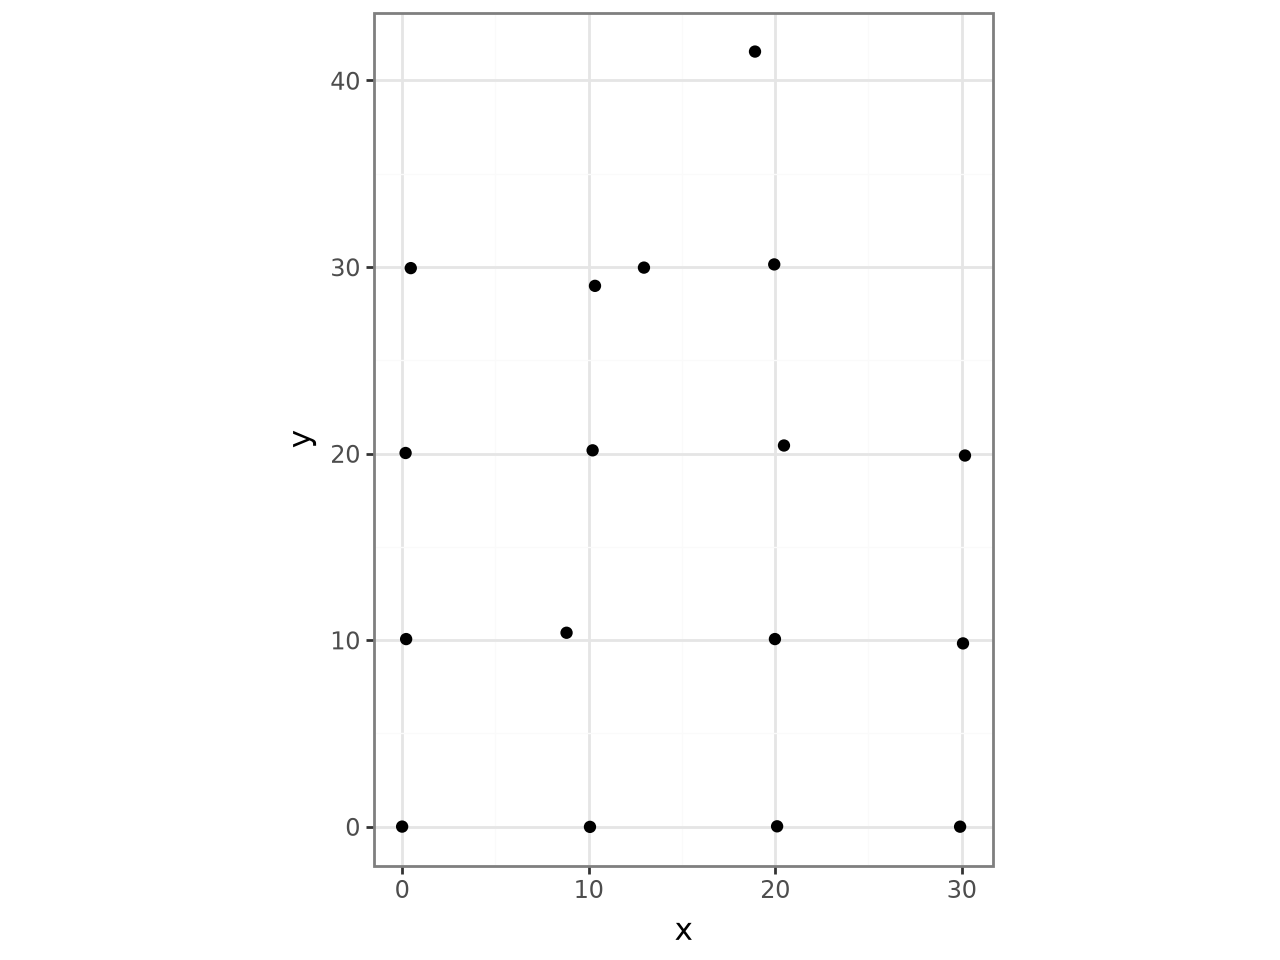

In [151]:
ggplot(pos_local, aes("x", "y")) + geom_point() + coord_fixed() + theme_bw()

let's remove the outliers

In [152]:
pos_local = pos_local.filter(c.y < 35, ~c.x.is_close(12.0, rel_tol=1e-1))
pos_local

x,y,label
f64,f64,str
20.470858,20.430667,"""20_20"""
0.4634,29.940939,"""0_30"""
10.070652,-0.015576,"""10_0"""
19.986525,10.053622,"""20_10"""
0.0,0.0,"""0_0"""
…,…,…
8.814776,10.391703,"""10_10"""
0.214884,10.052681,"""0_10"""
30.175033,19.893808,"""30_20"""


In [ ]:
perfect_grid = (
    pl.DataFrame({"x": range(0, 40, 10)})
    .join(pl.DataFrame({"y": range(0, 40, 10)}), how="cross")
    .with_columns(label=pl.format("{}_{}", pl.col("x"), pl.col("y")))
)

In [154]:
perfect_grid

x,y,label
i64,i64,str
0,0,"""0_0"""
0,10,"""0_10"""
0,20,"""0_20"""
0,30,"""0_30"""
10,0,"""10_0"""
…,…,…
20,30,"""20_30"""
30,0,"""30_0"""
30,10,"""30_10"""


In [ ]:
pos_local_perf = (
    pos_local.join(perfect_grid, on="label", how="full", suffix="_perfect")
    .with_columns(
        x_shift=c.x - c.x_perfect,
        y_shift=c.y - c.y_perfect,
    )
    .with_columns(diff=(c.x_shift**2 + c.y_shift**2).sqrt())
)
pos_local_perf

x,y,label,x_perfect,y_perfect,label_perfect,x_shift,y_shift,diff
f64,f64,str,i64,i64,str,f64,f64,f64
0.0,0.0,"""0_0""",0,0,"""0_0""",0.0,0.0,0.0
0.214884,10.052681,"""0_10""",0,10,"""0_10""",0.214884,0.052681,0.221247
0.185317,20.029358,"""0_20""",0,20,"""0_20""",0.185317,0.029358,0.187629
0.4634,29.940939,"""0_30""",0,30,"""0_30""",0.4634,-0.059061,0.467148
10.070652,-0.015576,"""10_0""",10,0,"""10_0""",0.070652,-0.015576,0.072348
…,…,…,…,…,…,…,…,…
19.949308,30.139094,"""20_30""",20,30,"""20_30""",-0.050692,0.139094,0.148043
29.913508,-0.004772,"""30_0""",30,0,"""30_0""",-0.086492,-0.004772,0.086624
30.069838,9.821623,"""30_10""",30,10,"""30_10""",0.069838,-0.178377,0.191561


c:\Users\smassaro\scanning\Bosland_subgridding\.pixi\envs\default\lib\python\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_bin : Removed 1 rows containing non-finite values.


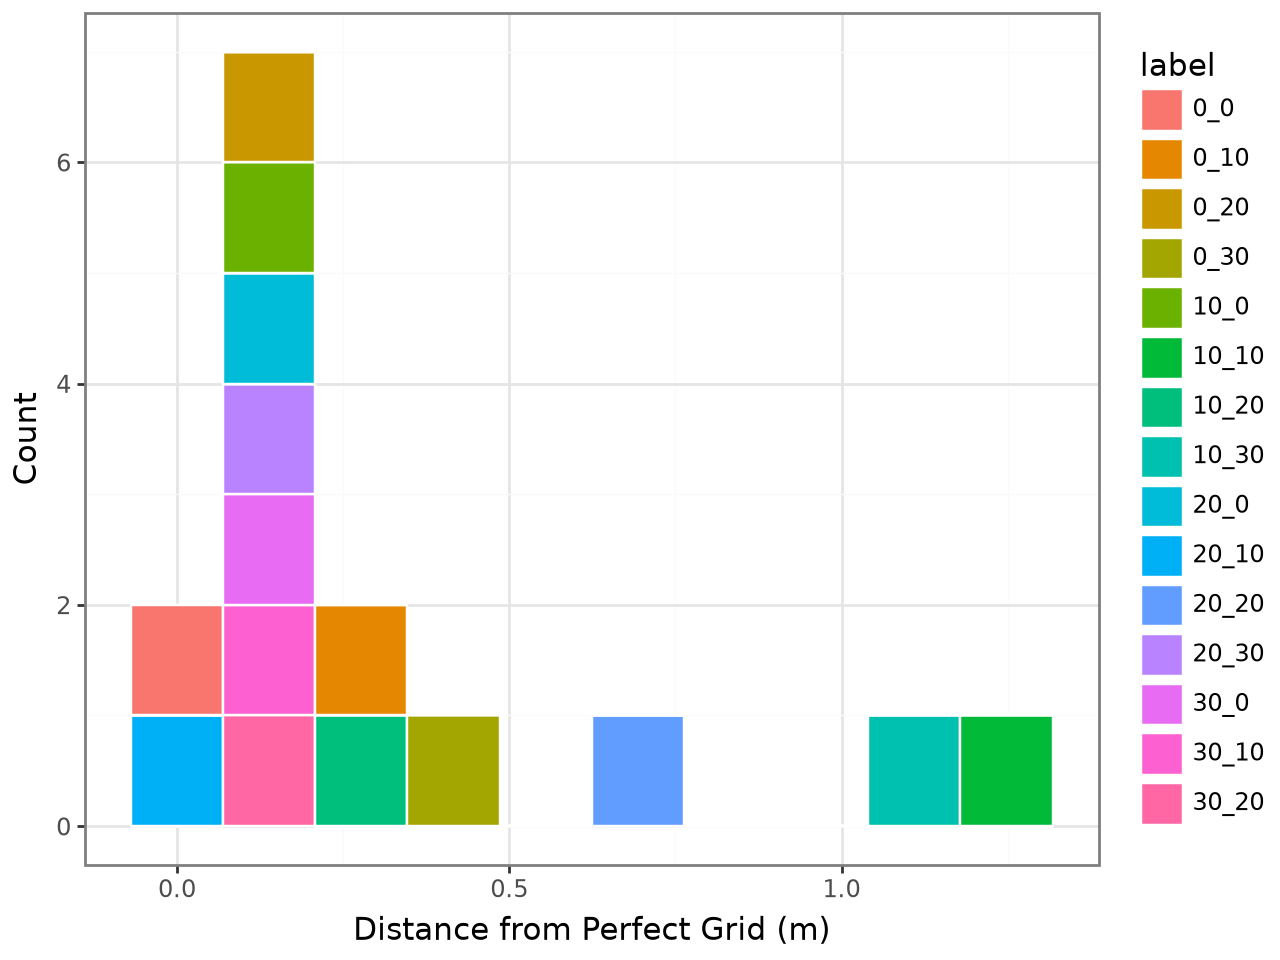

In [ ]:
pos_local_perf >> ggplot(aes("diff", fill="label")) + geom_histogram(
    bins=10, color="white"
) + theme_bw() + labs(x="Distance from Perfect Grid (m)", y="Count")

c:\Users\smassaro\scanning\Bosland_subgridding\.pixi\envs\default\lib\python\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_point : Removed 1 rows containing missing values.
c:\Users\smassaro\scanning\Bosland_subgridding\.pixi\envs\default\lib\python\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_text : Removed 1 rows containing missing values.


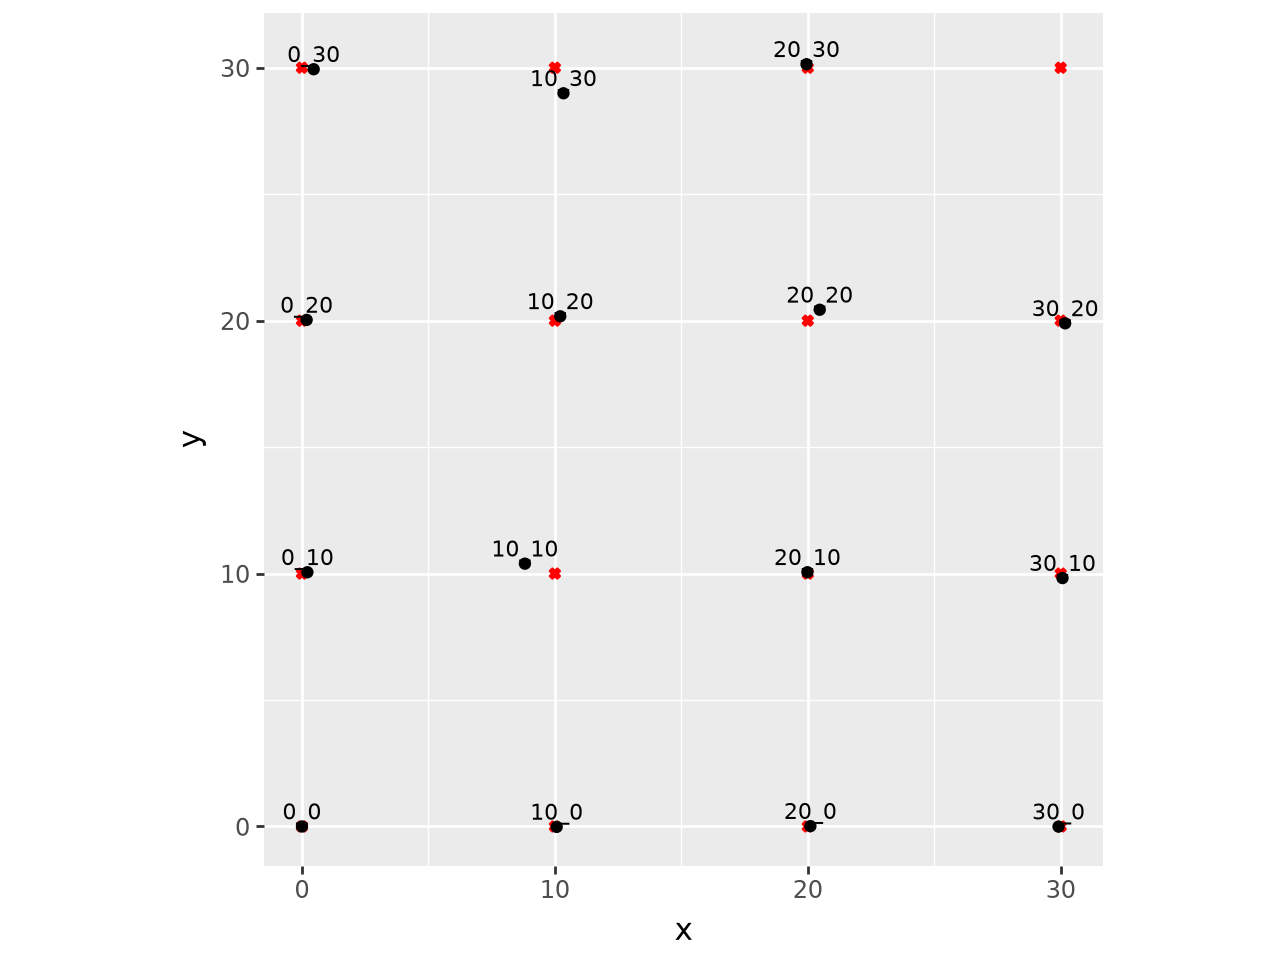

In [158]:
(
    ggplot(pos_local_perf, aes("x", "y", label="label"))
    + geom_point(aes("x_perfect", "y_perfect"), color="red", shape="X")
    + geom_point()
    + geom_text(nudge_y=0.5, size=8)
    + coord_fixed()
)

In [171]:
field_df = pos_local_perf.select(
    c.label,
    c.x_shift * 100,  # convert to cm
    c.y_shift * 100,  # convert to cm
).drop_nulls()
field_df

label,x_shift,y_shift
str,f64,f64
"""0_0""",0.0,0.0
"""0_10""",21.488364,5.268108
"""0_20""",18.531745,2.935827
"""0_30""",46.339954,-5.906086
"""10_0""",7.065191,-1.557597
…,…,…
"""20_20""",47.08577,43.066686
"""20_30""",-5.069162,13.909388
"""30_0""",-8.649247,-0.47721


In [164]:
from great_tables import GT

In [ ]:
field_table = (
    GT(field_df)
    .tab_header(
        title="Reflector Position Shifts (cm)",
    )
    .fmt_number(columns=["x_shift", "y_shift"], decimals=0)
    .tab_footnote(
        footnote="Shifts are in cm in local coordinate system\n. x -> east\n, y -> north."
    )
)
field_table

GT(_tbl_data=shape: (15, 3)
┌───────┬───────────┬────────────┐
│ label ┆ x_shift   ┆ y_shift    │
│ ---   ┆ ---       ┆ ---        │
│ str   ┆ f64       ┆ f64        │
╞═══════╪═══════════╪════════════╡
│ 0_0   ┆ 0.0       ┆ 0.0        │
│ 0_10  ┆ 21.488364 ┆ 5.268108   │
│ 0_20  ┆ 18.531745 ┆ 2.935827   │
│ 0_30  ┆ 46.339954 ┆ -5.906086  │
│ 10_0  ┆ 7.065191  ┆ -1.557597  │
│ …     ┆ …         ┆ …          │
│ 20_20 ┆ 47.08577  ┆ 43.066686  │
│ 20_30 ┆ -5.069162 ┆ 13.909388  │
│ 30_0  ┆ -8.649247 ┆ -0.47721   │
│ 30_10 ┆ 6.983757  ┆ -17.837743 │
│ 30_20 ┆ 17.503258 ┆ -10.619223 │
└───────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x000001A6BB6E6D50>, _boxhead=Boxhead([ColInfo(var='label', type=<ColInfoTypeEnum.default: 1>, column_label='label', column_align='left', column_width=None, stub_level=None), ColInfo(var='x_shift', type=<ColInfoTypeEnum.default: 1>, column_label='x_shift', column_align='right', column_width=None, stub_level=None), ColInfo(var='y_shift', type=<ColInfoTypeEnum.default: 1>, column_label='y_shift', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001A6BB5EB450>, _spanners=Spanners([]), _heading=Heading(title='Reflector Position Shifts (cm)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001A6BB6C7DD0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001A6BB6C7C50>, _source_notes=[], _footnotes=[FootnoteInfo(locname=None, grpname=None, colname=None, rownum=None, colnum=None, footnotes=['Shifts are in cm in local coordinate system\n. x -&gt; east\n, y -&gt; north.'], placement=<FootnotePlacement.auto: 3>)], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001A6BB5EB040>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001A6BB678E50>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border

In [191]:
field_df.write_csv("reflectors_positions_shifts_3x3_subplot_bosland_plot4.csv")

In [190]:
field_table.gtsave("reflectors_positions_shifts_3x3_subplot_bosland_plot4.pdf")

GT(_tbl_data=shape: (15, 3)
┌───────┬───────────┬────────────┐
│ label ┆ x_shift   ┆ y_shift    │
│ ---   ┆ ---       ┆ ---        │
│ str   ┆ f64       ┆ f64        │
╞═══════╪═══════════╪════════════╡
│ 0_0   ┆ 0.0       ┆ 0.0        │
│ 0_10  ┆ 21.488364 ┆ 5.268108   │
│ 0_20  ┆ 18.531745 ┆ 2.935827   │
│ 0_30  ┆ 46.339954 ┆ -5.906086  │
│ 10_0  ┆ 7.065191  ┆ -1.557597  │
│ …     ┆ …         ┆ …          │
│ 20_20 ┆ 47.08577  ┆ 43.066686  │
│ 20_30 ┆ -5.069162 ┆ 13.909388  │
│ 30_0  ┆ -8.649247 ┆ -0.47721   │
│ 30_10 ┆ 6.983757  ┆ -17.837743 │
│ 30_20 ┆ 17.503258 ┆ -10.619223 │
└───────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x000001A6BB6E6D50>, _boxhead=Boxhead([ColInfo(var='label', type=<ColInfoTypeEnum.default: 1>, column_label='label', column_align='left', column_width=None, stub_level=None), ColInfo(var='x_shift', type=<ColInfoTypeEnum.default: 1>, column_label='x_shift', column_align='right', column_width=None, stub_level=None), ColInfo(var='y_shift', type=<ColInfoTypeEnum.default: 1>, column_label='y_shift', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001A6BB5EB450>, _spanners=Spanners([]), _heading=Heading(title='Reflector Position Shifts (cm)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001A6BB6C7DD0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001A6BB6C7C50>, _source_notes=[], _footnotes=[FootnoteInfo(locname=None, grpname=None, colname=None, rownum=None, colnum=None, footnotes=['Shifts are in cm in local coordinate system\n. x -&gt; east\n, y -&gt; north.'], placement=<FootnotePlacement.auto: 3>)], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001A6BB5EB040>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001A6BB678E50>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border